# Patentes — Benja: modelo base
Segmenta los 6 caracteres de cada patente y los reconoce con un modelo simple. Reusa `patentes.py` sin cambios.

In [1]:
import os, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))
import modelo_benja as M

P = M.P          # patentes.py original, sin cambios

SALIDA = os.path.join(M.RAIZ, "images", "patentes_reconocidas_benja")

## Parte 1 — Método original
Corre `analizar_foto` de `patentes.py` sobre las 12 fotos.

In [2]:
base = {i: P.analizar_foto(M.ruta_foto(i)) for i in M.FOTOS}
for i, r in base.items():
    print(f"img{i:02d}  {r.estado:<11} detectadas {len(r.encontradas)}  deducidas {len(r.proyectadas)}")

img01  proyectado  detectadas 5  deducidas 1
img02  completo    detectadas 6  deducidas 0
img03  proyectado  detectadas 4  deducidas 2
img04  completo    detectadas 6  deducidas 0
img05  completo    detectadas 6  deducidas 0
img06  completo    detectadas 6  deducidas 0
img07  completo    detectadas 6  deducidas 0
img08  completo    detectadas 6  deducidas 0
img09  completo    detectadas 6  deducidas 0
img10  completo    detectadas 6  deducidas 0
img11  proyectado  detectadas 5  deducidas 1
img12  completo    detectadas 6  deducidas 0


## Parte 2 — Rotación
Estima la inclinación de la patente y endereza el recorte.

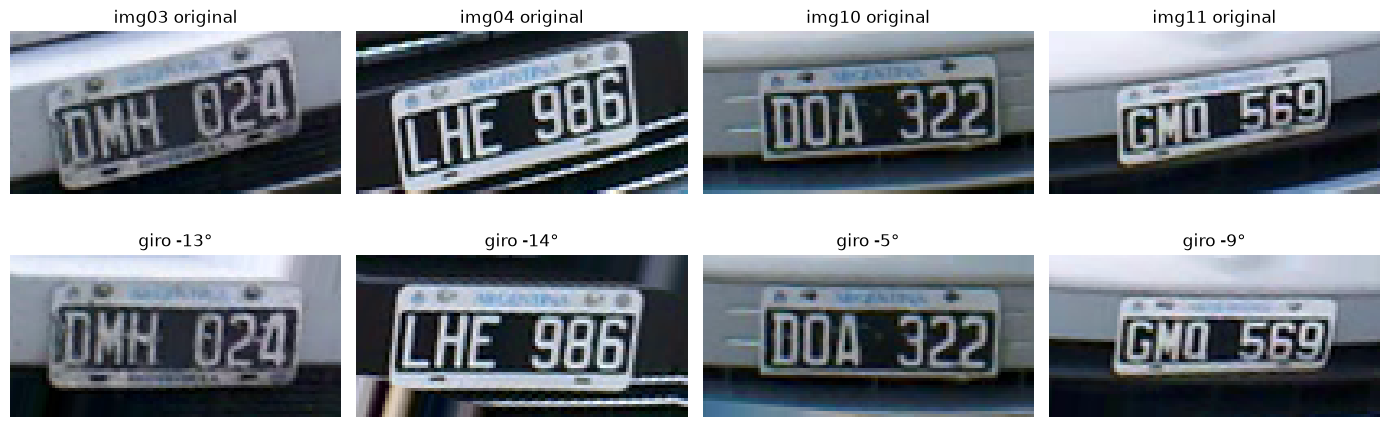

In [3]:
fig, ejes = plt.subplots(2, 4, figsize=(14, 5))
for k, i in enumerate((3, 4, 10, 11)):
    recorte = P.preparar_foto(M.ruta_foto(i))[0]
    angulo = M.estimar_angulo(recorte)
    ejes[0, k].imshow(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB)); ejes[0, k].set_title(f"img{i:02d} original")
    ejes[1, k].imshow(cv2.cvtColor(M.rotar(recorte, angulo), cv2.COLOR_BGR2RGB)); ejes[1, k].set_title(f"giro {angulo:+.0f}°")
for e in ejes.ravel(): e.axis("off")
plt.tight_layout(); plt.show()

## Parte 3 — Binarización múltiple
32 versiones de cada recorte: 4 fuentes de gris (gris, L de CIELAB, V de HSV, ecualizado) × 8 binarizaciones (umbrales, Otsu, top-hat).

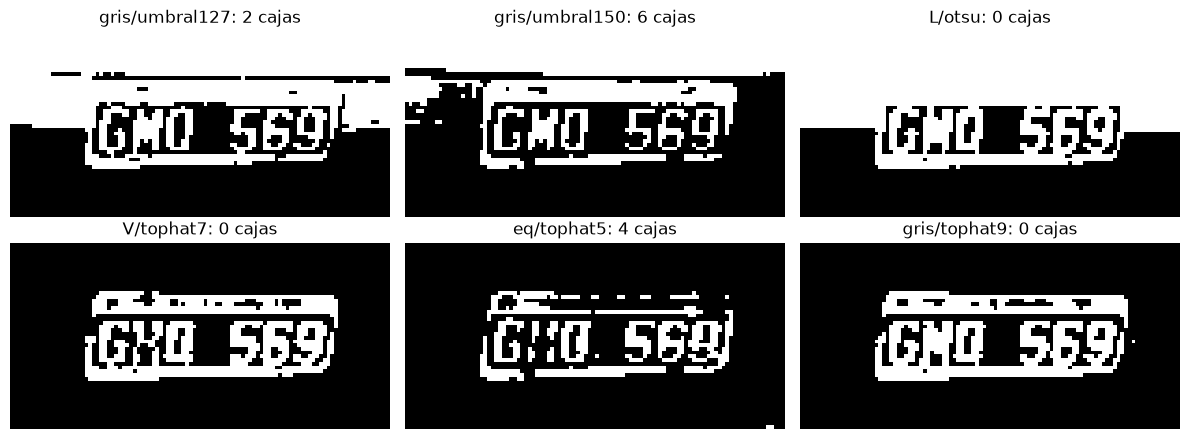

img11: 3 de 32 versiones encuentran 6 cajas


In [4]:
recorte = P.preparar_foto(M.ruta_foto(11))[0]
rotada = M.rotar(recorte, M.estimar_angulo(recorte))
vs = M.variantes(rotada)
fig, ejes = plt.subplots(2, 3, figsize=(12, 4.5))
for e, nombre in zip(ejes.ravel(), ["gris/umbral127", "gris/umbral150", "L/otsu", "V/tophat7", "eq/tophat5", "gris/tophat9"]):
    e.imshow(vs[nombre], cmap="gray"); e.axis("off")
    e.set_title(f"{nombre}: {len(M.cajas_de_variante(vs[nombre]))} cajas")
plt.tight_layout(); plt.show()
print(f"img11: {sum(len(M.cajas_de_variante(b)) == 6 for b in vs.values())} de {len(vs)} versiones encuentran 6 cajas")

## Parte 4 — Segmentación por consenso
Elige la versión más parecida a la mediana entre las que encuentran 6 cajas. Si ninguna llega, completa con la geometría original.

In [5]:
tp = M.cargar_tp()
for i, r in tp.items():
    print(f"img{i:02d}  giro {r['angulo']:+3.0f}°  {r['metodo']:<10} {r['version']:<16} cajas {len(r['cajas'])}")
print("patentes con 6 cajas:", sum(len(r["cajas"]) == 6 for r in tp.values()), "de 12")

img01  giro  -7°  consenso   V/tophat7        cajas 6
img02  giro  -9°  consenso   gris/umbral110   cajas 6
img03  giro -13°  geometria  gris/umbral110   cajas 6
img04  giro -14°  consenso   gris/tophat9     cajas 6
img05  giro -10°  consenso   gris/umbral110   cajas 6
img06  giro  -8°  consenso   gris/tophat7     cajas 6
img07  giro  +0°  consenso   gris/umbral110   cajas 6
img08  giro  -8°  consenso   gris/umbral127   cajas 6
img09  giro  +0°  consenso   L/umbral127      cajas 6
img10  giro  -5°  consenso   gris/umbral150   cajas 6
img11  giro  -9°  consenso   gris/umbral150   cajas 6
img12  giro  -5°  consenso   gris/umbral127   cajas 6


patentes con 6 cajas: 12 de 12


## Parte 5 — Reconocimiento
Cada carácter se reduce a una huella de 8 × 12 píxeles y se compara con los de las otras patentes (vecino más cercano).
Cada patente se lee dejándola afuera de las referencias.

In [6]:
lecturas, res = M.evaluar(tp, M.armar_referencias(tp))
for i in M.FOTOS:
    print(f"img{i:02d}  leída {lecturas[i]}  real {M.ETIQUETAS[i]}  {res['aciertos'][i]}/6")
print(f"\nletras {res['letras']}/36   números {res['numeros']}/36   patentes completas {res['completas']}/12")

img01  leída BOF917  real BUF817  4/6
img02  leída OXQ796  real GXQ798  4/6
img03  leída OMH624  real DMH024  4/6
img04  leída LME998  real LHE986  3/6
img05  leída FJX344  real FJY344  5/6
img06  leída LEH892  real LEH992  5/6
img07  leída LDD123  real LOD123  5/6
img08  leída JMD337  real JMO337  5/6
img09  leída FFO705  real FFD765  4/6
img10  leída DQD322  real DOA322  4/6
img11  leída GMU569  real GMQ569  5/6
img12  leída OQX387  real BQX387  5/6

letras 24/36   números 29/36   patentes completas 0/12


## Parte 6 — Resultado por patente
Guarda una imagen por patente y un `resumen.csv` en `images/patentes_reconocidas_benja/`.

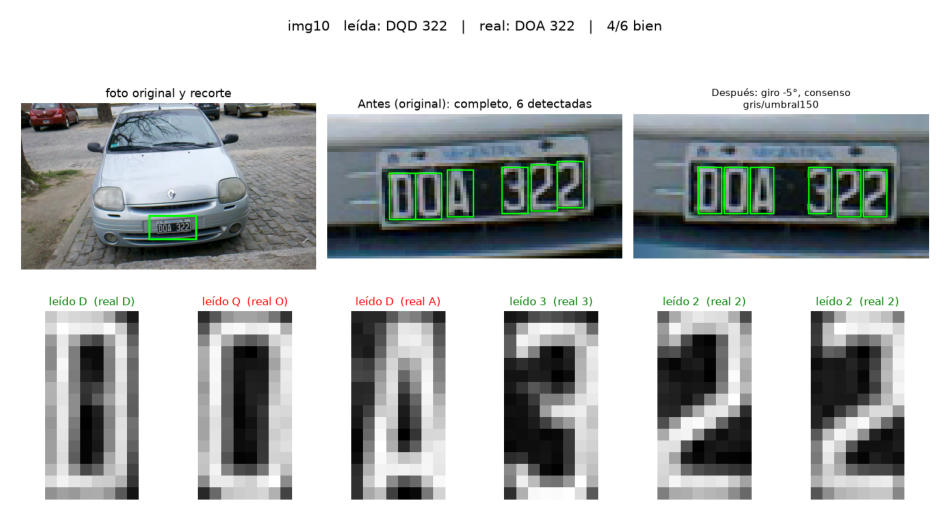

guardado en C:\Users\Benja\Documents\Facultad\3\cuatri_dos\imagenes\tp_procesamiento_de_imagenes_2\images\patentes_reconocidas_benja


In [7]:
M.guardar_resultados(SALIDA, tp, base, lecturas)
plt.figure(figsize=(12, 6.5)); plt.imshow(plt.imread(f"{SALIDA}/patente_10.png")); plt.axis("off"); plt.show()
print("guardado en", SALIDA)